# 03 · Cohortes Comparables, Estructuras Motoras y Definición Normativa de `Hardware OK`

**Ticket 4.5 (Issue #31)** · Consolida los pasos analíticos **4.3, 4.4 y 4.5** acordados con el experto clínico (Dr. Tiberio).

**Decisiones vinculadas:** [DEC-016](file:///docs/decisiones.md), [DEC-026](file:///docs/decisiones.md), [DEC-029](file:///docs/decisiones.md), [DEC-030](file:///docs/decisiones.md), [DEC-031](file:///docs/decisiones.md)

> **Privacidad de datos (DEC-001 / DEC-005):** Este notebook consume el módulo oficial `src.features.build_hardware_ok` y reporta exclusivamente **estadísticos agregados** (conteos, medias, DE, medianas, IQR, tamaños de efecto, IC 95% y valores $q_{\text{FDR}}$). Ninguna celda imprime ni exporta filas o identificadores individuales de pacientes.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.features.build_hardware_ok import build_hardware_ok_pipeline

sns.set_theme(style="whitegrid", font="sans-serif")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

hw_ok_df, reports = build_hardware_ok_pipeline()
print(
    f"Muestra analítica prematuros (fit_sample): n = {len(hw_ok_df)} "
    f"(qc_ok: n = {int(hw_ok_df['qc_ok'].sum())})"
)

Muestra analítica prematuros (fit_sample): n = 209 (qc_ok: n = 168)


## 1. Grupos Comparables, Sensibilidad RCIU-Fenton y Tabla 1 Descriptiva (Paso 4.3 / DEC-029)

Comparamos el grupo de **Referencia a Término (`ubicac == 3`, $\text{EG} \ge 37\text{ sem}$, $\text{peso} \ge 2500\text{ g}$)** con resonancia magnética, **excluyendo los 9 sujetos con `rciu_fenton_ref == True`** ($n = 28$; la referencia completa, $n = 37$, queda como sensibilidad, DEC-040) frente al grupo de **Prematuros `< 1801 g` (`fit_sample`, $n = 209$, y submuestra `qc_ok`, $n = 168$)** en variables perinatales (`BIRTH`) y sociodemográficas (`SCB`).

In [2]:
tabla1 = reports["tabla1_cohortes"]
cont_cols = [
    "variable",
    "n_ref_mri",
    "ref_mri_mean_or_pct",
    "ref_mri_sd",
    "ref_mri_median",
    "n_ref_completa",
    "ref_completa_mean_or_pct",
    "n_preterm_fit",
    "preterm_fit_mean_or_pct",
    "preterm_fit_sd",
    "hedges_g_pre_vs_ref",
    "p_value_welch",
    "p_value_mwu",
]
print(
    "=== TABLA 1A: VARIABLES CONTINUAS (REFERENCIA CON RM vs. PREMATUROS FIT_SAMPLE) ==="
)
display(tabla1.loc[tabla1["kind"] == "continuous", cont_cols].round(3))

cat_cols = [
    "variable",
    "n_ref_mri",
    "ref_mri_mean_or_pct",
    "n_ref_completa",
    "ref_completa_mean_or_pct",
    "n_preterm_fit",
    "preterm_fit_mean_or_pct",
    "n_preterm_qc",
    "preterm_qc_mean_or_pct",
]
print("\n=== TABLA 1B: VARIABLES CATEGÓRICAS (% POR NIVEL) ===")
display(tabla1.loc[tabla1["kind"] == "categorical_pct", cat_cols].round(1))

=== TABLA 1A: VARIABLES CONTINUAS (REFERENCIA CON RM vs. PREMATUROS FIT_SAMPLE) ===


,variable,n_ref_mri,ref_mri_mean_or_pct,ref_mri_sd,ref_mri_median,n_ref_completa,ref_completa_mean_or_pct,n_preterm_fit,preterm_fit_mean_or_pct,preterm_fit_sd,hedges_g_pre_vs_ref,p_value_welch,p_value_mwu
0,BIRTH_peso5,28,3155.179,299.368,3157.5,37,3032.081,209,1558.110,233.073,-6.589,0.000,0.000
1,BIRTH_ballar5,28,39.036,1.036,39.0,37,38.973,209,33.077,2.545,-2.455,0.000,0.000
2,BIRTH_talla5,27,495.556,16.946,490.0,36,488.333,207,407.053,31.650,-2.906,0.000,0.000
3,BIRTH_pc5,19,343.474,11.172,345.0,28,340.571,166,299.205,17.584,-2.584,0.000,0.000
4,SCB_agemother,28,24.571,5.494,22.5,37,24.378,208,28.274,5.704,0.650,0.002,0.001
5,SCB_percap1,28,112236.310,89171.219,90000.0,37,117106.757,208,84129.808,56381.782,-0.459,0.115,0.185



=== TABLA 1B: VARIABLES CATEGÓRICAS (% POR NIVEL) ===


,variable,n_ref_mri,ref_mri_mean_or_pct,n_ref_completa,ref_completa_mean_or_pct,n_preterm_fit,preterm_fit_mean_or_pct,n_preterm_qc,preterm_qc_mean_or_pct
6,BIRTH_sexo5==1,28,53.6,37,51.4,209,58.4,168,60.1
7,BIRTH_sexo5==2,28,46.4,37,48.6,209,41.6,168,39.9
8,BIRTH_cesarea==0,28,100.0,37,100.0,208,30.3,168,30.4
9,BIRTH_cesarea==1,28,0.0,37,0.0,208,69.7,168,69.6
10,BIRTH_RCIUFenton==0,28,100.0,37,75.7,209,54.1,168,51.8
11,BIRTH_RCIUFenton==1,28,0.0,37,24.3,209,45.9,168,48.2
12,SCB_civilstatus==1,28,75.0,37,75.7,209,86.6,168,85.7
13,SCB_civilstatus==2,28,25.0,37,24.3,209,13.4,168,14.3
14,SCB_nivm1==1,28,28.6,37,21.6,209,16.7,168,18.5
15,SCB_nivm1==2,28,53.6,37,59.5,209,57.4,168,56.0


## 2. Caracterización del NHPT, Concordancia Bimanual y Normas Lateralizadas de Mathiowetz (1985)

Describimos `NHPT_promedioMD`, `NHPT_promedioMND`, la reconstrucción lateralizada (`nhpt_right` y `nhpt_left` según `NHPT_ManoDominante`), el promedio bimanual `nhpt_mean` y el puntaje estandarizado contra la referencia local (`z_nhpt_ref`). Verificamos además la concordancia bimanual ($r = 0.660$) y el contraste frente a las normas por sexo de Mathiowetz et al. (1985, Tablas 3 y 4, 20–24 años: mujeres derecha $15.8 \pm 2.1\text{ s}$, izquierda $17.2 \pm 2.4\text{ s}$; hombres derecha $16.1 \pm 1.9\text{ s}$, izquierda $16.8 \pm 2.2\text{ s}$).

In [3]:
nhpt_df = reports["nhpt_por_grupo"]
concordance = reports["calibracion_hardware_ok"]["nhpt_bimanual_concordance"]
print(
    "=== CONCORDANCIA BIMANUAL Y DESPLAZAMIENTO EN REFERENCIA vs. MATHIOWETZ (1985) ==="
)
for k, v in concordance.items():
    print(f"  {k:42s}: {v:.4f}" if isinstance(v, float) else f"  {k:42s}: {v}")

print("\n=== CARACTERIZACIÓN DE NHPT POR GRUPO Y CONTRASTE CON MATHIOWETZ (1985) ===")
nhpt_cols_show = [
    "group",
    "metric",
    "n",
    "mean",
    "sd",
    "median",
    "iqr",
    "hedges_g_vs_ref",
    "p_welch_vs_ref",
    "diff_vs_mathiowetz_1985_s",
    "z_vs_mathiowetz_1985",
    "pct_slower_than_mathiowetz_1985",
]
display(nhpt_df[nhpt_cols_show].round(3))

=== CONCORDANCIA BIMANUAL Y DESPLAZAMIENTO EN REFERENCIA vs. MATHIOWETZ (1985) ===
  n_both_hands_total                        : 483
  pearson_r_total                           : 0.6557
  pearson_p_total                           : 0.0000
  spearman_rho_total                        : 0.4949
  pearson_r_fit_sample                      : 0.7424
  pearson_p_fit_sample                      : 0.0000
  mean_diff_mnd_minus_md_s                  : 1.7204
  ref_n_lateralized                         : 37
  ref_z_math_right_mean                     : 1.0459
  ref_z_math_left_mean                      : 1.1416
  ref_z_math_bimanual_mean                  : 1.0938
  ref_pct_slower_than_mathiowetz_right      : 91.8919
  ref_pct_slower_than_mathiowetz_left       : 86.4865
  ref_pct_slower_than_mathiowetz_bimanual   : 97.2973

=== CARACTERIZACIÓN DE NHPT POR GRUPO Y CONTRASTE CON MATHIOWETZ (1985) ===


,group,metric,n,mean,sd,median,iqr,hedges_g_vs_ref,p_welch_vs_ref,diff_vs_mathiowetz_1985_s,z_vs_mathiowetz_1985,pct_slower_than_mathiowetz_1985
0,referencia_total_nhpt,NHPT_promedioMD,49,17.633,1.439,17.500,2.000,-0.125,0.560,1.865,NaN,85.714
1,referencia_total_nhpt,NHPT_promedioMND,49,19.888,2.486,19.000,3.000,-0.012,0.955,2.702,NaN,87.755
2,referencia_total_nhpt,nhpt_right,49,17.806,1.513,18.000,2.000,-0.147,0.494,1.865,0.930,85.714
3,referencia_total_nhpt,nhpt_left,49,19.714,2.588,19.000,3.000,0.004,0.984,2.702,1.166,87.755
4,referencia_total_nhpt,nhpt_mean,49,18.760,1.564,18.500,2.500,-0.067,0.758,2.284,1.048,97.959
5,referencia_total_nhpt,z_nhpt_ref,49,-0.176,1.055,0.000,1.686,0.067,0.758,NaN,NaN,NaN
6,referencia_mri_nhpt,NHPT_promedioMD,27,17.907,1.408,18.000,1.500,0.069,0.785,2.178,NaN,92.593
7,referencia_mri_nhpt,NHPT_promedioMND,27,19.426,2.147,19.000,2.750,-0.206,0.402,2.200,NaN,85.185
8,referencia_mri_nhpt,nhpt_right,27,18.111,1.515,18.000,1.250,0.056,0.824,2.178,1.091,92.593
9,referencia_mri_nhpt,nhpt_left,27,19.222,2.203,18.500,2.250,-0.193,0.431,2.200,0.954,85.185


## 3. Contraste Anatómico Término vs. Prematuros en Valores Absolutos (Paso 4.4 / DEC-016 / DEC-030)

Siguiendo estrictamente **DEC-016**, comparamos el `icv` y las **80 ROIs motoras en valores absolutos** (excluyendo las columnas `*_icvadj` dado que el ICV es un desenlace de la prematurez). Como los prematuros presentan mayor FA y menor RD que la referencia a término en el tracto corticoespinal por pérdida de fibras cruzadas (Groeschel et al., 2014), fijamos la **Lista Corta de 12 Volúmenes Motores (`SHORTLIST_CORE_VOL_12`) como definición principal** de `hardware_ok`, manteniendo las 18 métricas de 3 dominios (`SHORTLIST_3DOMAIN_18`) como análisis de sensibilidad.

ROIs del atlas principal con q_FDR < 0.05 (Welch o MWU): 32 / 65

=== TOP 25 ESTRUCTURAS MOTORAS POR |g DE HEDGES| (VALORES ABSOLUTOS, PREMATUROS vs. TÉRMINO) ===


,roi,family,in_shortlist_vol12,in_shortlist_18,mean_preterm,mean_ref,hedges_g,hedges_g_ci95_low,hedges_g_ci95_high,cliffs_delta,p_welch,q_fdr_welch_primary65,q_fdr_mwu_primary65,hedges_g_qc_ok,hedges_g_ref_completa
63,ba_rh_ba1_curv,brodmann_m1_s1,False,False,1.882000e-01,1.650000e-01,0.9876,0.5832,1.3921,0.6372,0.0000,0.0000,0.0000,1.0943,0.9053
1,sub_lh_caudate_vol,basal_ganglia,True,True,3.396453e+03,3.842789e+03,-0.8966,-1.2993,-0.4939,-0.4798,0.0000,0.0002,0.0004,-0.9245,-0.7503
80,cst_rh_vol,corticospinal_tract,True,True,1.039139e+03,1.270321e+03,-0.8712,-1.2734,-0.4690,-0.5005,0.0000,0.0003,0.0004,-0.8212,-0.8218
41,sub_rh_caudate_vol,basal_ganglia,True,True,3.646926e+03,4.082414e+03,-0.8471,-1.2489,-0.4453,-0.4696,0.0001,0.0006,0.0005,-0.9063,-0.7049
67,ba_rh_ba2_curv,brodmann_m1_s1,False,False,1.259000e-01,1.116000e-01,0.8416,0.4399,1.2433,0.5299,0.0000,0.0000,0.0002,0.9226,0.5982
43,sub_rh_pallidum_vol,basal_ganglia,True,True,1.482836e+03,1.688864e+03,-0.8332,-1.2348,-0.4316,-0.4164,0.0022,0.0085,0.0021,-0.7991,-0.7688
23,ba_lh_ba1_curv,brodmann_m1_s1,False,False,1.875000e-01,1.686000e-01,0.7714,0.3709,1.1720,0.4807,0.0000,0.0000,0.0004,0.8929,0.7137
7,ba_lh_ba4a_curv,brodmann_m1_s1,False,False,1.345000e-01,1.187000e-01,0.7267,0.3268,1.1266,0.4481,0.0000,0.0000,0.0009,0.7931,0.6875
47,ba_rh_ba4a_curv,brodmann_m1_s1,False,False,1.329000e-01,1.152000e-01,0.7265,0.3266,1.1264,0.4296,0.0000,0.0000,0.0015,0.7398,0.6888
51,ba_rh_ba4p_curv,brodmann_m1_s1,False,False,1.155000e-01,1.017000e-01,0.6935,0.2941,1.0929,0.4638,0.0000,0.0000,0.0006,0.7343,0.6185


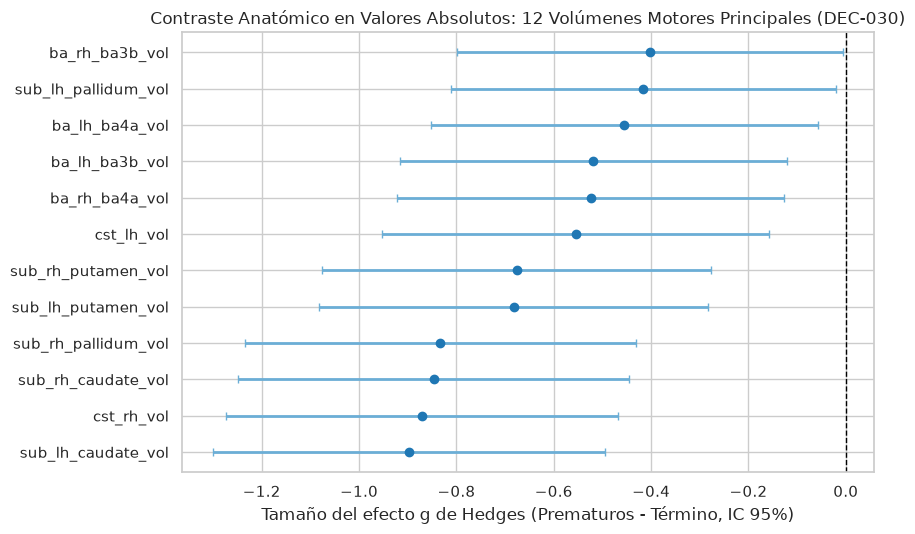

In [4]:
rois_df = reports["contraste_80_rois_absolutas"].copy()
prim_rois = rois_df.loc[rois_df["is_primary_atlas"]].copy()
prim_rois = prim_rois.reindex(
    prim_rois["hedges_g"].abs().sort_values(ascending=False).index
)

show_roi_cols = [
    "roi",
    "family",
    "in_shortlist_vol12",
    "in_shortlist_18",
    "mean_preterm",
    "mean_ref",
    "hedges_g",
    "hedges_g_ci95_low",
    "hedges_g_ci95_high",
    "cliffs_delta",
    "p_welch",
    "q_fdr_welch_primary65",
    "q_fdr_mwu_primary65",
    "hedges_g_qc_ok",
    "hedges_g_ref_completa",
]
n_sig = int(
    (
        (prim_rois["q_fdr_welch_primary65"] < 0.05)
        | (prim_rois["q_fdr_mwu_primary65"] < 0.05)
    ).sum()
)
print(
    f"ROIs del atlas principal con q_FDR < 0.05 (Welch o MWU): {n_sig} / {len(prim_rois)}"
)
print(
    "\n=== TOP 25 ESTRUCTURAS MOTORAS POR |g DE HEDGES| (VALORES ABSOLUTOS, PREMATUROS vs. TÉRMINO) ==="
)
display(prim_rois[show_roi_cols].head(25).round(4))

# Visualización agregada (Forest plot de los 12 volúmenes motores principales de SHORTLIST_CORE_VOL_12)
sl12_df = rois_df.loc[rois_df["in_shortlist_vol12"]].sort_values("hedges_g")
fig, ax = plt.subplots(figsize=(9, 5.5))
y_pos = np.arange(len(sl12_df))
ax.errorbar(
    sl12_df["hedges_g"],
    y_pos,
    xerr=[
        sl12_df["hedges_g"] - sl12_df["hedges_g_ci95_low"],
        sl12_df["hedges_g_ci95_high"] - sl12_df["hedges_g"],
    ],
    fmt="o",
    color="#1f77b4",
    ecolor="#6baed6",
    elinewidth=2,
    capsize=3,
)
ax.axvline(0.0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y_pos)
ax.set_yticklabels(sl12_df["roi"])
ax.set_xlabel("Tamaño del efecto g de Hedges (Prematuros - Término, IC 95%)")
ax.set_title(
    "Contraste Anatómico en Valores Absolutos: 12 Volúmenes Motores Principales (DEC-030)"
)
plt.tight_layout()
plt.show()

## 4. Asociación Estructura–NHPT en Prematuros y Calibración Normativa de `hardware_ok` (Paso 4.5 / DEC-031)

Evaluamos en prematuros (`fit_sample` $n = 209$ y `qc_ok` $n = 168$) la correlación parcial y regresión ajustada por `BIRTH_sexo5` entre las métricas seleccionadas (absolutas e `*_icvadj`) y el tiempo en NHPT (`nhpt_mean`). Finalmente, verificamos la distribución de `hardware_ok` (`SHORTLIST_CORE_VOL_12 >= -1.0`) y sus variantes de sensibilidad (`hardware_ok_ref_completa`, `hardware_ok_sex`, `hardware_ok_3domain18` y `hardware_ok_count`) para el Ticket #33 (`5.2`).

In [5]:
assoc_df = reports["asociacion_estructura_nhpt"].copy()
assoc_sorted = assoc_df.reindex(
    assoc_df["partial_r_fit"].abs().sort_values(ascending=False).index
)
assoc_cols = [
    "feature",
    "scale_type",
    "n_fit",
    "partial_r_fit",
    "partial_r_ci95_low_fit",
    "partial_r_ci95_high_fit",
    "p_value_fit",
    "q_fdr_fit",
    "ols_beta_s_per_sd_fit",
    "huber_beta_s_per_sd_fit",
    "partial_r_qc",
    "p_value_qc",
]
print("=== ASOCIACIÓN ESTRUCTURA-NHPT AJUSTADA POR SEXO (TOP 20 EN FIT_SAMPLE) ===")
display(assoc_sorted[assoc_cols].head(20).round(4))

cal_df = pd.DataFrame(reports["calibracion_hardware_ok"]["calibration_candidates"])
print("\n=== CALIBRACIÓN DE CRITERIOS CANDIDATOS PARA HARDWARE_OK (DEC-031) ===")
display(cal_df.round(1))

print("\n=== RESUMEN AGREGADO DE DATA/FEATURES/HARDWARE_OK.PARQUET ===")
score_cols = [
    "hw_norm_score",
    "hw_norm_score_ref_completa",
    "hw_norm_score_sex",
    "hw_norm_score_3domain18",
    "n_impaired_structures",
    "nhpt_mean",
    "z_nhpt_ref",
]
summary_stats = hw_ok_df[score_cols].astype(float).describe().T
display(summary_stats.round(3))

=== ASOCIACIÓN ESTRUCTURA-NHPT AJUSTADA POR SEXO (TOP 20 EN FIT_SAMPLE) ===


,feature,scale_type,n_fit,partial_r_fit,partial_r_ci95_low_fit,partial_r_ci95_high_fit,p_value_fit,q_fdr_fit,ols_beta_s_per_sd_fit,huber_beta_s_per_sd_fit,partial_r_qc,p_value_qc
41,ba_rh_ba2_curv,absolute_or_composite,209,0.3372,0.2109,0.4525,0.0000,0.0000,0.9263,0.3669,0.2940,0.0001
46,hw_norm_score_sex,absolute_or_composite,209,-0.3019,-0.4207,-0.1730,0.0000,0.0002,-0.8416,-0.4257,-0.2313,0.0026
39,ba_rh_ba3b_curv,absolute_or_composite,209,0.2996,0.1705,0.4186,0.0000,0.0002,0.8245,0.2666,0.2270,0.0031
47,hw_norm_score_3domain18,absolute_or_composite,209,-0.2927,-0.4123,-0.1631,0.0000,0.0002,-0.8691,-0.4777,-0.2081,0.0068
3,sub_rh_putamen_vol,absolute_or_composite,209,-0.2764,-0.3975,-0.1459,0.0001,0.0005,-0.8067,-0.2614,-0.2382,0.0019
42,hw_motor,absolute_or_composite,209,-0.2707,-0.3923,-0.1398,0.0001,0.0006,-0.7462,-0.3720,-0.1474,0.0565
45,hw_norm_score_vol12,absolute_or_composite,209,-0.2642,-0.3864,-0.1329,0.0001,0.0007,-0.7925,-0.4350,-0.1977,0.0102
44,hw_norm_score,absolute_or_composite,209,-0.2642,-0.3864,-0.1329,0.0001,0.0007,-0.7925,-0.4350,-0.1977,0.0102
21,sub_rh_putamen_vol_icvadj,icv_adjusted,209,-0.2613,-0.3837,-0.1299,0.0001,0.0007,-0.7192,-0.1949,-0.2061,0.0073
0,sub_lh_caudate_vol,absolute_or_composite,209,-0.2557,-0.3785,-0.1239,0.0002,0.0009,-0.7069,-0.3590,-0.2183,0.0045



=== CALIBRACIÓN DE CRITERIOS CANDIDATOS PARA HARDWARE_OK (DEC-031) ===


,criterion,n_fit_total,n_fit_ok,pct_fit_ok,n_qc_total,n_qc_ok,pct_qc_ok
0,hardware_ok_main_vol12_ge_m1sd,209,98,46.9,168,84,50.0
1,hardware_ok_ref_completa_vol12_ge_m1sd,209,93,44.5,168,79,47.0
2,hardware_ok_sex_vol12_ge_m1sd,209,79,37.8,168,65,38.7
3,hardware_ok_3domain18_ge_m1sd,209,99,47.4,168,87,51.8
4,hardware_ok_count_le2_of_12,209,77,36.8,168,64,38.1
5,rejected_strict_intersection_0_of_12,209,20,9.6,168,15,8.9



=== RESUMEN AGREGADO DE DATA/FEATURES/HARDWARE_OK.PARQUET ===


,count,mean,std,min,25%,50%,75%,max
hw_norm_score,209.0,-1.098,1.124,-5.119,-1.753,-1.060,-0.452,2.406
hw_norm_score_ref_completa,209.0,-1.275,1.258,-5.811,-2.016,-1.241,-0.515,2.664
hw_norm_score_sex,209.0,-1.419,1.325,-6.731,-2.071,-1.317,-0.528,1.894
hw_norm_score_3domain18,209.0,-1.184,1.833,-11.093,-2.155,-1.076,0.080,3.387
n_impaired_structures,209.0,4.110,3.090,0.000,2.000,4.000,6.000,12.000
nhpt_mean,209.0,19.170,2.752,14.500,17.700,18.500,20.000,35.750
z_nhpt_ref,209.0,-0.452,1.856,-11.635,-1.012,0.000,0.540,2.698
